<a href="https://colab.research.google.com/github/DungeonProgger/IOS-Android/blob/main/Pract2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Подготовка данных и инициализация API ВКонтакте
В данном блоке происходит подключение к API ВКонтакте с использованием сервисного ключа (access_token). Наш исходный датасет содержит 33 ссылки на профили студентов группы БСМО-11,12-26.

Поскольку для построения графа связей методы API требуют использования числовых идентификаторов, на первом этапе скрипт автоматически обрабатывает исходный список с помощью метода `users.get`, конвертируя буквенные ссылки (screen_names) в стандартные ID. Также здесь инициализируется наша целевая подгруппа из 3 человек, результаты которой будут оцениваться в конце.

In [ ]:
import requests
import time
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations

# ВСТАВЬТЕ ВАШ СЕРВИСНЫЙ КЛЮЧ СЮДА:
TOKEN = "a6e68db0a6e68db0a6e68db023a5a2f5f8aa6e6a6e68db0cc2b8a1195522cffae0e0790".strip()
API_VERSION = "5.199"

# Полный объединенный список группы (33 человека)
group_urls_all = [
    "https://vk.ru/metonimiaa", "https://vk.ru/pizdec2286", "https://vk.ru/kotletosss", "https://vk.ru/antonlevn",
    "https://vk.ru/s.abramov2", "https://vk.ru/dimabazlov", "https://vk.ru/gs1ayer",
    "https://vk.ru/daioru", "https://vk.ru/freezefinn", "https://vk.ru/fed_serega",
    "https://vk.ru/rskator", "https://vk.ru/rudnev911", "https://vk.ru/fulliener",
    "https://vk.ru/id830638754", "https://vk.ru/1nkarat", "https://vk.ru/id1098513955",
    "https://vk.ru/ogponcha", "https://vk.ru/andrew.kirillov", "https://m.vk.ru/bignigga",
    "https://vk.ru/y.doyneko", "https://vk.ru/saulinivan", "https://vk.ru/dimitr101",
    "https://vk.ru/ku_ku_riz", "https://vk.ru/medvediano", "https://vk.ru/flashik12",
    "https://vk.ru/0pupok00", "https://vk.ru/ryosuk3", "https://vk.ru/id139159408",
    "https://vk.ru/dedvnutree", "https://vk.ru/votkakblat", "https://vk.ru/sh3rryy",
    "https://vk.ru/asstynj", "https://vk.ru/foreverlostintears", "https://vk.ru/max_d_saf"
]

# Ваша целевая команда для анализа
team_ids = [172152768, 301455650, 222943197]
short_names = [url.strip().split('/')[-1] for url in group_urls_all]

session = requests.Session()

res_users = session.get("https://api.vk.com/method/users.get", params={
    "user_ids": ",".join(short_names),
    "access_token": TOKEN,
    "v": API_VERSION
}).json()

all_group_ids = []
id_to_name = {}

if "response" in res_users:
    print(f"=== Состав учебной группы БСМО-11-26 (распознано {len(res_users['response'])} из {len(group_urls_all)}) ===")
    for u in res_users["response"]:
        uid = u["id"]
        name = f"{u.get('first_name', '')} {u.get('last_name', '')}".strip()
        all_group_ids.append(uid)
        id_to_name[uid] = name
        print(f"  ID {uid}: {name}")
else:
    print("Ошибка API при вызове users.get:", res_users)

# Гарантируем, что ваша подгруппа есть в итоговом списке обхода
for tid in team_ids:
    if tid not in all_group_ids:
        all_group_ids.append(tid)

def get_friends(user_id, show_errors=False):
    url = "https://api.vk.com/method/friends.get"
    params = {"user_id": user_id, "access_token": TOKEN, "v": API_VERSION}
    for attempt in range(3):
        try:
            res = session.get(url, params=params, timeout=10).json()
            if "response" in res:
                return res["response"]["items"]
            elif "error" in res:
                err_code = res["error"].get("error_code")
                # 6 = Too many requests, 30 = Private profile, 15 = Access denied, 18 = User deleted
                if err_code == 6:
                    time.sleep(1.0)
                    continue
                if show_errors and err_code not in (30, 15, 18):
                    print(f"    [ID {user_id}: код ошибки {err_code} - {res['error'].get('error_msg')}]")
                return []
        except Exception:
            time.sleep(0.5)
    return []

=== Состав учебной группы БСМО-11-26 (распознано 34 из 34) ===
  ID 214576903: Artem Kuzmin
  ID 222943197: Dmitry Rozhdestvensky
  ID 147436715: Maria Alexandrova
  ID 708207289: Le Khiep-Khy
  ID 354792455: Sergey Abramov
  ID 437474057: Dmitry Bazlov
  ID 193511426: Alexander Vasilyev
  ID 229017385: Kirill Kucherenko
  ID 133821410: Kirill Drenin
  ID 172152768: Sergey Fedkin
  ID 677045683: Ruslan Allabergenov
  ID 278508214: Ilya Rudnev
  ID 392942223: Ruslän Dächev
  ID 830638754: Klim Volokhov
  ID 241970575: Nikita Markov
  ID 1098513955: Dmitry Yadovity
  ID 301455650: Ilya Burmistrov
  ID 357111839: Andrey Kirillov
  ID 447383697: Igor Susarov
  ID 365680993: Yulia Doyneko
  ID 223966628: Ivan Saulin
  ID 299547783: Dmitry Poluektov
  ID 288851914: Denis Davydov
  ID 465105120: Ilya Medvedev
  ID 198182178: Alexander Ershov
  ID 473310225: Lia Martynova
  ID 424935969: Vladimir Romanenko
  ID 139159408: Daniil Nisanov
  ID 236434667: Alexander Goloktionov
  ID 270876280: Gle

### 2. Сбор прямых контактов (1-й уровень графа)
Алгоритм начинает обход списка группы, отправляя запросы к методу `friends.get` для получения прямых друзей каждого студента.

Политика конфиденциальности ВКонтакте позволяет пользователям полностью или частично скрывать свои страницы. Если скрипт выводит `найдено 0 друзей`, это означает, что профиль закрыт настройками приватности (возвращается код ошибки API 30: *This profile is private*), скрипт обрабатывает такие системные ответы: он игнорирует закрытые профили и продолжает сбор по открытым страницам.

In [ ]:
edges = []
friends_1hop = set(all_group_ids)

for uid in all_group_ids:
    f_list = get_friends(uid, show_errors=True)
    friends_1hop.update(f_list)
    for f in f_list:
        edges.append((uid, f))
    print(f"  {id_to_name.get(uid, f'ID {uid}')}: найдено {len(f_list)} друзей")
    time.sleep(0.35)

all_1hop_list = [u for u in friends_1hop if u not in all_group_ids]
print(f"\nВсего уникальных друзей 1-го уровня для проверки на следующем шаге: {len(all_1hop_list)}")

  Artem Kuzmin: найдено 0 друзей
  Dmitry Rozhdestvensky: найдено 0 друзей
  Maria Alexandrova: найдено 112 друзей
  Le Khiep-Khy: найдено 111 друзей
  Sergey Abramov: найдено 0 друзей
  Dmitry Bazlov: найдено 0 друзей
  Alexander Vasilyev: найдено 0 друзей
  Kirill Kucherenko: найдено 0 друзей
  Kirill Drenin: найдено 127 друзей
  Sergey Fedkin: найдено 0 друзей
  Ruslan Allabergenov: найдено 0 друзей
  Ilya Rudnev: найдено 104 друзей
  Ruslän Dächev: найдено 210 друзей
  Klim Volokhov: найдено 18 друзей
  Nikita Markov: найдено 87 друзей
  Dmitry Yadovity: найдено 1 друзей
  Ilya Burmistrov: найдено 0 друзей
  Andrey Kirillov: найдено 256 друзей
  Igor Susarov: найдено 104 друзей
  Yulia Doyneko: найдено 0 друзей
  Ivan Saulin: найдено 153 друзей
  Dmitry Poluektov: найдено 0 друзей
  Denis Davydov: найдено 105 друзей
  Ilya Medvedev: найдено 181 друзей
  Alexander Ershov: найдено 0 друзей
  Lia Martynova: найдено 177 друзей
  Vladimir Romanenko: найдено 30 друзей
  Daniil Nisanov: н

### 3. Формирование графа «друзей друзей» (2-й уровень)
Для построения глубоких социальных связей мы берем всех уникальных людей, найденных на первом шаге, и собираем списки контактов уже для них.

Этот процесс требует отправки тысяч запросов. Чтобы ВКонтакте не заблокировал доступ из-за превышения лимитов (ошибка API 6: *Too many requests per second*), в алгоритм встроена система автоповтора с динамическими паузами. По завершении парсинга все найденные социальные связи (ребра графа) экспортируются в файл `Data_Full_Graph.csv`, что позволяет сохранить структуру сети без необходимости повторного парсинга при перезапуске среды Colab.

In [ ]:
if len(all_1hop_list) > 0:
    print("Шаг 2: Полный сбор друзей друзей (2-й уровень)...")
    for idx, f_id in enumerate(all_1hop_list):
        f_of_f = get_friends(f_id, show_errors=False)
        for target in f_of_f:
            edges.append((f_id, target))

        if (idx + 1) % 100 == 0 or (idx + 1) == len(all_1hop_list):
            print(f"  Проверено профилей: {idx + 1} из {len(all_1hop_list)} (собрано связей: {len(edges)})")
        time.sleep(0.35)

    df_api = pd.DataFrame(edges, columns=['Source', 'Target'])
    df_api.to_csv('Data_Full_Graph.csv', index=False, sep=';')

    G = nx.from_pandas_edgelist(df_api, source='Source', target='Target')
    print(f"\nСбор завершен! Полный граф сохранен. Узлов: {G.number_of_nodes()}, Ребер: {G.number_of_edges()}.")
else:
    print("Ошибка: Список друзей пуст. Убедитесь, что токен работает и профили открыты.")

Шаг 2: Полный сбор друзей друзей (2-й уровень)...
  Проверено профилей: 100 из 2040 (собрано связей: 17719)
  Проверено профилей: 200 из 2040 (собрано связей: 43667)
  Проверено профилей: 300 из 2040 (собрано связей: 66851)
  Проверено профилей: 400 из 2040 (собрано связей: 85367)
  Проверено профилей: 500 из 2040 (собрано связей: 98650)
  Проверено профилей: 600 из 2040 (собрано связей: 116280)
  Проверено профилей: 700 из 2040 (собрано связей: 138328)
  Проверено профилей: 800 из 2040 (собрано связей: 154953)
  Проверено профилей: 900 из 2040 (собрано связей: 179975)
  Проверено профилей: 1000 из 2040 (собрано связей: 192608)
  Проверено профилей: 1100 из 2040 (собрано связей: 212192)
  Проверено профилей: 1200 из 2040 (собрано связей: 227935)
  Проверено профилей: 1300 из 2040 (собрано связей: 243772)
  Проверено профилей: 1400 из 2040 (собрано связей: 254960)
  Проверено профилей: 1500 из 2040 (собрано связей: 270535)
  Проверено профилей: 1600 из 2040 (собрано связей: 285625)
  Пр

### 4. Анализ целевой подгруппы и расчет метрик центральности
Собранный массив данных загружается в объект графа библиотеки `networkx`. В этом блоке мы вычисляем процент охвата сети (сколько людей доступно через друзей и друзей друзей) и рассчитываем три ключевые метрики центральности для нашей рабочей команды из 3 человек на фоне всей остальной сети:

1. **Посредничество (Betweenness Centrality):** Показывает, насколько часто участник выступает связующим мостом (посредником) на кратчайших путях между другими узлами графа.
2. **Близость (Closeness Centrality):** Отражает среднюю топологическую дистанцию от участника до всех остальных профилей (чем выше метрика, тем быстрее информация от этого узла распространится по сети).
3. **Собственный вектор (Eigenvector Centrality):** Оценивает качественную «влиятельность» профиля. Метрика растет, если участник связан с другими очень общительными и центральными узлами, а не просто с профилями-одиночками.

=== Анализ охвата связей (для команды из 3 человек) ===
Студент Sergey Fedkin:
  Прямых друзей (1 шаг): 1
  Друзей друзей (2 шага): 551
  Охват графа за 2 рукопожатия: 0.20%
-------------------------------------------------------
Студент Ilya Burmistrov:
  Прямых друзей (1 шаг): 1
  Друзей друзей (2 шага): 81
  Охват графа за 2 рукопожатия: 0.03%
-------------------------------------------------------
Студент Dmitry Rozhdestvensky:
  Прямых друзей (1 шаг): 4
  Друзей друзей (2 шага): 537
  Охват графа за 2 рукопожатия: 0.19%
-------------------------------------------------------

=== Общие друзья между участниками команды ===
Между Sergey Fedkin и Ilya Burmistrov: 0 общих
Между Sergey Fedkin и Dmitry Rozhdestvensky: 0 общих
Между Ilya Burmistrov и Dmitry Rozhdestvensky: 0 общих

Рассчитываем метрики центральности (подождите ~30-60 секунд)...

=== Результаты метрик центральности (для команды) ===
Sergey Fedkin:
  Посредничество: 0.000000
  Близость:       0.205121
  Собств. вектор: 0.0

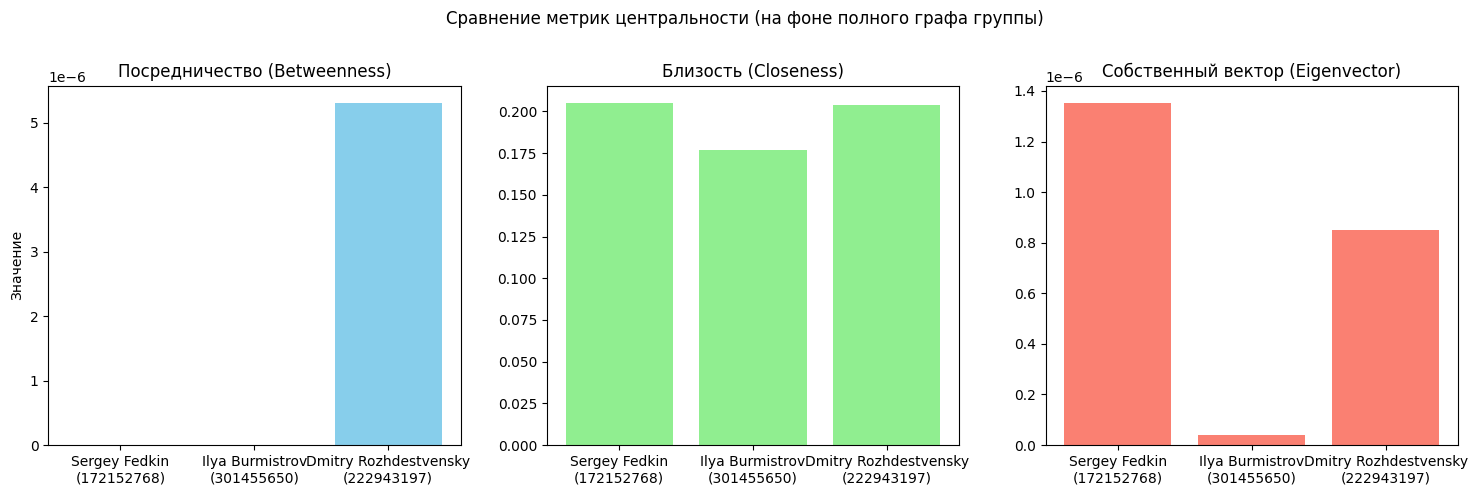

In [ ]:
if 'G' in locals() and len(G) > 0:
    print("=== Анализ охвата связей (для команды из 3 человек) ===")
    for uid in team_ids:
        if uid in G:
            f1 = set(G.neighbors(uid))
            f2 = set()
            for friend in f1:
                f2.update(G.neighbors(friend))
            f2.discard(uid)
            f2 -= f1

            reach = ((len(f1) + len(f2)) / G.number_of_nodes()) * 100
            name_str = id_to_name.get(uid, f"ID {uid}")
            print(f"Студент {name_str}:")
            print(f"  Прямых друзей (1 шаг): {len(f1)}")
            print(f"  Друзей друзей (2 шага): {len(f2)}")
            print(f"  Охват графа за 2 рукопожатия: {reach:.2f}%")
            print("-" * 55)

    print("\n=== Общие друзья между участниками команды ===")
    for u1, u2 in combinations(team_ids, 2):
        if u1 in G and u2 in G:
            common = list(nx.common_neighbors(G, u1, u2))
            print(f"Между {id_to_name.get(u1, str(u1))} и {id_to_name.get(u2, str(u2))}: {len(common)} общих")

    print("\nРассчитываем метрики центральности (подождите ~30-60 секунд)...")
    k_sample = min(400, G.number_of_nodes())
    betweenness = nx.betweenness_centrality(G, k=k_sample, seed=42)
    closeness = {uid: nx.closeness_centrality(G, u=uid) for uid in team_ids if uid in G}

    try:
        eigenvector = nx.eigenvector_centrality(G, max_iter=500)
    except Exception:
        eigenvector = {node: 0 for node in G.nodes()}

    labels, b_vals, c_vals, e_vals = [], [], [], []

    print("\n=== Результаты метрик центральности (для команды) ===")
    for uid in team_ids:
        if uid in G.nodes():
            b = betweenness.get(uid, 0)
            c = closeness.get(uid, 0)
            e = eigenvector.get(uid, 0)

            name_str = id_to_name.get(uid, str(uid))
            labels.append(f"{name_str}\n({uid})")
            b_vals.append(b)
            c_vals.append(c)
            e_vals.append(e)

            print(f"{name_str}:")
            print(f"  Посредничество: {b:.6f}")
            print(f"  Близость:       {c:.6f}")
            print(f"  Собств. вектор: {e:.6f}")
            print("-" * 70)

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle('Сравнение метрик центральности (на фоне полного графа группы)')

    ax1.bar(labels, b_vals, color='skyblue')
    ax1.set_title('Посредничество (Betweenness)')
    ax1.set_ylabel('Значение')

    ax2.bar(labels, c_vals, color='lightgreen')
    ax2.set_title('Близость (Closeness)')

    ax3.bar(labels, e_vals, color='salmon')
    ax3.set_title('Собственный вектор (Eigenvector)')

    plt.tight_layout()
    plt.show()
else:
    print("Граф G не найден или пуст. Сначала выполните Ячейку 3.")